# 常微分方程式 1

初期値問題を数値的に解く方法を実装します。Euler法、RK2法、RK4法、連立方程式、硬い方程式、陰解法、適応刻み幅制御を順に扱います。

## 初期値問題

1階常微分方程式の初期値問題は
$$
\frac{dx}{dt}=f(x,t),\qquad x(t_0)=x_0
$$
です。解は積分方程式
$$
x(t)=x_0+\int_{t_0}^{t} f(x(t'),t')\,dt'
$$
を満たします。ここでは時間発展を数値的に近似します。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def integrate(step, f, x0, t0, h, nsteps):
    t = t0 + h * np.arange(nsteps + 1)
    x = np.empty((nsteps + 1,) + np.shape(x0), dtype=float)
    x[0] = x0
    for n in range(nsteps):
        x[n + 1] = step(f, x[n], t[n], h)
    return t, x

## Euler法

Taylor展開を1次で打ち切ると
$$
x(t+h)=x(t)+h\frac{dx}{dt}+\mathcal{O}(h^2)
\quad\Longrightarrow\quad
x_{n+1}=x_n+h f(x_n,t_n).
$$
1ステップの局所誤差は $\mathcal{O}(h^2)$、区間全体での大域誤差は $\mathcal{O}(h)$ です。

In [2]:
def euler_step(f, x, t, h):
    return x + h * f(x, t)

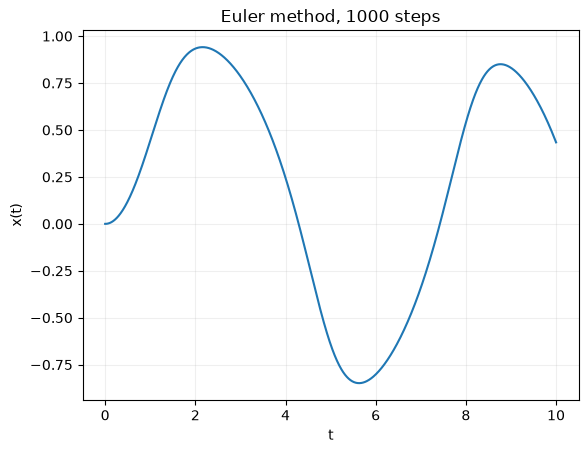

In [3]:
def f(x, t):
    return -x**3 + np.sin(t)

t0, tend, x0 = 0.0, 10.0, 0.0
t_euler, x_euler = integrate(
    euler_step, f, x0, t0, (tend - t0) / 1000, 1000
)
plt.plot(t_euler, x_euler)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Euler method, 1000 steps")
plt.grid(alpha=0.2)
plt.show()

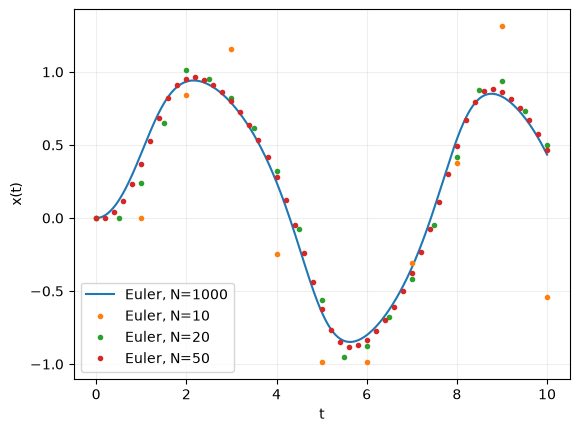

In [4]:
plt.plot(t_euler, x_euler, label="Euler, N=1000")
for nsteps in (10, 20, 50):
    t, x = integrate(euler_step, f, x0, t0,
                     (tend - t0) / nsteps, nsteps)
    plt.plot(t, x, "o", ms=3, label=f"Euler, N={nsteps}")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 中点法（RK2）

Euler法は傾きを区間の始点だけで評価します。中点法は中間点の傾きを使います。
$$
\begin{aligned}
k_1&=h f(x_n,t_n),\\
k_2&=h f(x_n+k_1/2,t_n+h/2),\\
x_{n+1}&=x_n+k_2.
\end{aligned}
$$
局所誤差は $\mathcal{O}(h^3)$、大域誤差は $\mathcal{O}(h^2)$ です。

In [5]:
def rk2_step(f, x, t, h):
    k1 = h * f(x, t)
    k2 = h * f(x + k1 / 2, t + h / 2)
    return x + k2

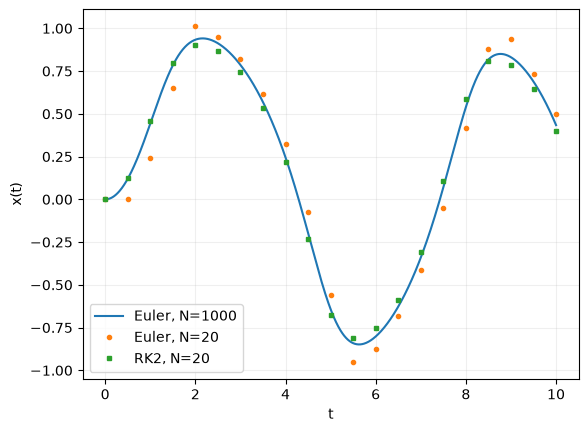

In [6]:
nsteps = 20
h = (tend - t0) / nsteps
t_e, x_e = integrate(euler_step, f, x0, t0, h, nsteps)
t_2, x_2 = integrate(rk2_step, f, x0, t0, h, nsteps)
plt.plot(t_euler, x_euler, label="Euler, N=1000")
plt.plot(t_e, x_e, "o", ms=3, label="Euler, N=20")
plt.plot(t_2, x_2, "s", ms=3, label="RK2, N=20")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 4次Runge--Kutta法（RK4）

4段階の傾きを重み付き平均します。
$$
\begin{aligned}
k_1&=h f(x_n,t_n),\\
k_2&=h f(x_n+k_1/2,t_n+h/2),\\
k_3&=h f(x_n+k_2/2,t_n+h/2),\\
k_4&=h f(x_n+k_3,t_n+h),\\
x_{n+1}&=x_n+(k_1+2k_2+2k_3+k_4)/6.
\end{aligned}
$$
局所誤差は $\mathcal{O}(h^5)$、大域誤差は $\mathcal{O}(h^4)$ です。

In [7]:
def rk4_step(f, x, t, h):
    k1 = h * f(x, t)
    k2 = h * f(x + k1 / 2, t + h / 2)
    k3 = h * f(x + k2 / 2, t + h / 2)
    k4 = h * f(x + k3, t + h)
    return x + (k1 + 2*k2 + 2*k3 + k4) / 6

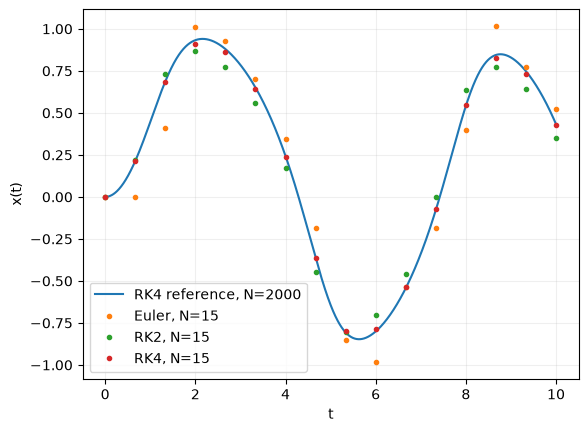

In [8]:
reference = integrate(
    rk4_step, f, x0, t0, (tend - t0) / 2000, 2000
)
nsteps = 15
h = (tend - t0) / nsteps
solutions = {
    "Euler": integrate(euler_step, f, x0, t0, h, nsteps),
    "RK2": integrate(rk2_step, f, x0, t0, h, nsteps),
    "RK4": integrate(rk4_step, f, x0, t0, h, nsteps),
}
plt.plot(reference[0], reference[1], label="RK4 reference, N=2000")
for name, (t, x) in solutions.items():
    plt.plot(t, x, "o", ms=3, label=f"{name}, N=15")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [9]:
# 解析解が分かるテスト問題で、次数の違いを確認する
def decay(x, t):
    return -x

errors = {}
for name, step in (("Euler", euler_step),
                   ("RK2", rk2_step), ("RK4", rk4_step)):
    _, values = integrate(step, decay, 1.0, 0.0, 0.1, 10)
    errors[name] = abs(values[-1] - np.exp(-1))
assert errors["RK4"] < errors["RK2"] < errors["Euler"]
assert errors["RK4"] < 1e-6
print(errors)

{'Euler': np.float64(0.019201001071442347), 'RK2': np.float64(0.0006615436621095205), 'RK4': np.float64(3.3324105608301124e-07)}


## 連立1階方程式

状態をベクトル $\mathbf{x}=(x_1,\ldots,x_N)$ とすれば、
$$
\frac{d\mathbf{x}}{dt}=\mathbf{f}(\mathbf{x},t)
$$
と書けます。同じ時間積分法をベクトルの各成分に適用できます。

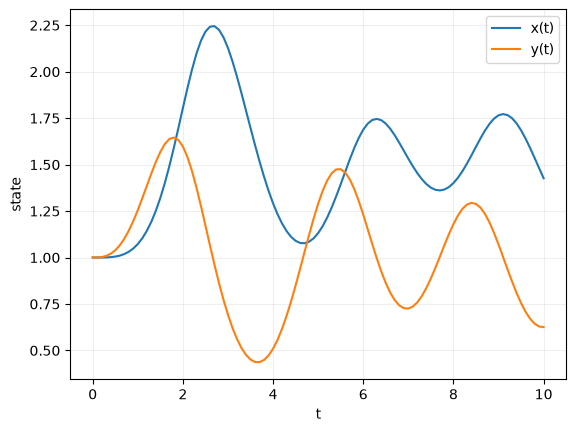

In [10]:
def coupled_rhs(x, t):
    a, b = x
    return np.array([a*b - a, b - a*b + np.sin(t)**2])

t_c, x_c = integrate(
    rk4_step, coupled_rhs, np.array([1.0, 1.0]),
    0.0, 0.1, 100
)
plt.plot(t_c, x_c[:, 0], label="x(t)")
plt.plot(t_c, x_c[:, 1], label="y(t)")
plt.xlabel("t")
plt.ylabel("state")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 2階方程式を1階連立系へ

運動方程式のような2階ODE
$$
\frac{d^2\mathbf{q}}{dt^2}
=\mathbf{F}(\mathbf{q},d\mathbf{q}/dt,t)
$$
は速度 $\mathbf{v}=d\mathbf{q}/dt$ を導入して
$$
\frac{d}{dt}
\begin{pmatrix}\mathbf{q}\\\mathbf{v}\end{pmatrix}
=
\begin{pmatrix}\mathbf{v}\\\mathbf{F}(\mathbf{q},\mathbf{v},t)\end{pmatrix}
$$
とすれば、$2N$ 元の1階連立系として解けます。

## 陽解法・陰解法と硬い方程式

試験問題 $dx/dt=-cx$（$c>0$）の解析解は $x(t)=e^{-ct}x_0$ です。
前進Euler法では
$$
x_{n+1}=(1-ch)x_n.
$$
数値解が減衰する条件は $|1-ch|<1$、すなわち $0<h<2/c$ です。急速な減衰と遅い時間尺度が共存すると、安定性のため刻み幅を極端に小さくする必要があり、硬い方程式と呼ばれます。

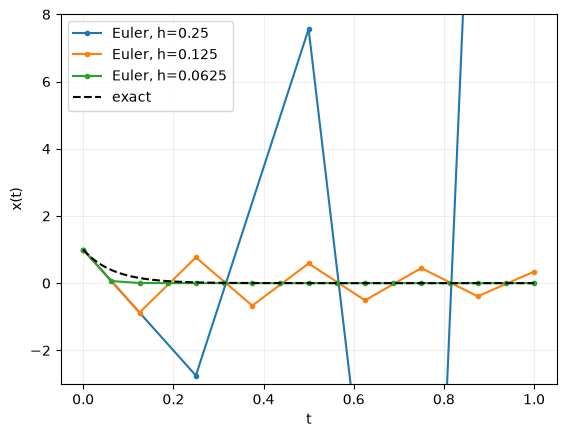

In [11]:
def stiff_rhs(x, t):
    return -15.0 * x

t_exact = np.linspace(0, 1, 300)
x_exact = np.exp(-15 * t_exact)
for h in (1/4, 1/8, 1/16):
    n = round(1 / h)
    t, x = integrate(euler_step, stiff_rhs, 1.0, 0.0, h, n)
    plt.plot(t, x, "o-", ms=3, label=f"Euler, h={h:g}")
plt.plot(t_exact, x_exact, "k--", label="exact")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.ylim(-3, 8)
plt.legend()
plt.grid(alpha=0.2)
plt.show()

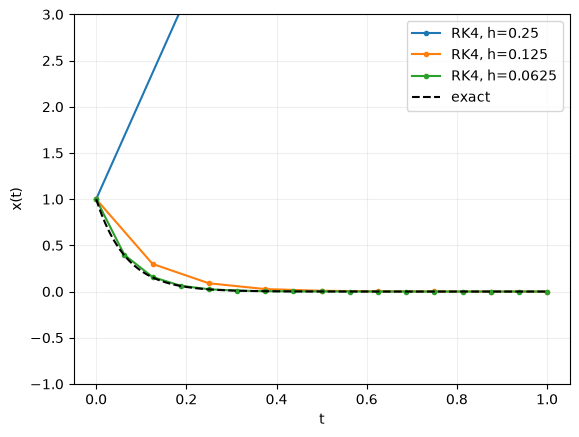

In [12]:
for h in (1/4, 1/8, 1/16):
    n = round(1 / h)
    t, x = integrate(rk4_step, stiff_rhs, 1.0, 0.0, h, n)
    plt.plot(t, x, "o-", ms=3, label=f"RK4, h={h:g}")
plt.plot(t_exact, x_exact, "k--", label="exact")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.ylim(-1, 3)
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 後退Euler法

後退Euler法は次の時刻の値を右辺に含みます。
$$
x_{n+1}=x_n+h f(x_{n+1},t_{n+1}).
$$
$f(x,t)=-cx$ では代数的に解け、
$$
x_{n+1}=\frac{x_n}{1+ch}.
$$
一般の非線形方程式では、各ステップで方程式を解く必要があります。陰解法は安定性を得やすい一方、計算量が増えます。

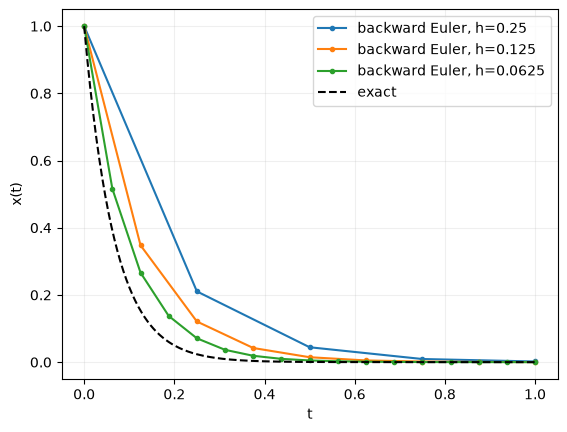

In [13]:
def backward_euler_decay(x0, h, nsteps, c=15.0):
    t = h * np.arange(nsteps + 1)
    x = np.empty(nsteps + 1)
    x[0] = x0
    for n in range(nsteps):
        x[n + 1] = x[n] / (1 + c*h)
    return t, x

for h in (1/4, 1/8, 1/16):
    n = round(1 / h)
    t, x = backward_euler_decay(1.0, h, n)
    plt.plot(t, x, "o-", ms=3, label=f"backward Euler, h={h:g}")
plt.plot(t_exact, x_exact, "k--", label="exact")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

後退Euler法は $c,h>0$ なら増幅率 $1/(1+ch)$ が $0$ と $1$ の間にあり、どの正の刻み幅でも数値解は発散しません。ただし大きな $h$ では、安定でも解析解の減衰を正確に表せません。

## 適応刻み幅制御

刻み幅を大きくしすぎると誤差が増え、小さくしすぎると計算を浪費します。RK4で長さ $h$ の1ステップと、長さ $h/2$ の2ステップを比較します。
$$
e \simeq \frac{|x_{h/2}^{(2)}-x_h|}{2^4-1}
=\frac{|x_{h/2}^{(2)}-x_h|}{15}.
$$
$error\le\mathrm{tol}$なら2つの半ステップ解を採用し、誤差が大きければ刻み幅を縮めます。誤差が $h^5$ に比例するので、刻み幅の更新には5乗根を使います。

In [14]:
def rk4_adaptive(f, x0, t0, t_end, h0, tol=1e-6):
    t = float(t0)
    x = np.asarray(x0, dtype=float)
    ts, xs = [t], [x.copy()]
    h = h0
    while t < t_end:
        h = min(h, t_end - t)
        full = rk4_step(f, x, t, h)
        half = rk4_step(
            f, rk4_step(f, x, t, h/2), t + h/2, h/2
        )
        error = np.max(np.abs(half - full)) / 15
        if not np.isfinite(error) or not np.isfinite(h):
            raise RuntimeError("non-finite RK4 step; reduce initial step size h0")
        factor = (2.0 if error == 0 else
                  np.clip(0.9 * (tol / error)**0.2, 0.2, 2.0))
        if error <= tol:
            t += h
            x = half
            ts.append(t)
            xs.append(x.copy())
        h *= factor
        if t < t_end and h <= np.finfo(float).eps * max(1, abs(t)):
            raise RuntimeError("step size underflow")
    return np.asarray(ts), np.asarray(xs)

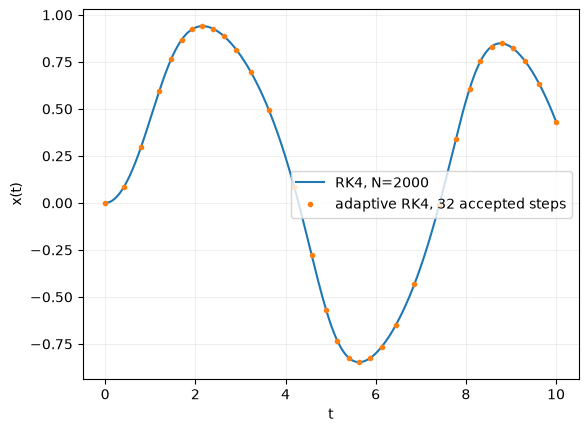

accepted steps = 6


In [15]:
def nonlinear_rhs(x, t):
    return -x**3 + np.sin(t)

t_adapt, x_adapt = rk4_adaptive(
    nonlinear_rhs, 0.0, 0.0, 10.0, 1.0, tol=1e-5
)
assert np.isfinite(t_adapt).all() and t_adapt[-1] == 10.0
with np.errstate(over="ignore", invalid="ignore"):
    try:
        rk4_adaptive(nonlinear_rhs, 1.0, 0.0, 10.0, 10.0, tol=1e-5)
    except RuntimeError as exc:
        assert "reduce initial step size" in str(exc)
    else:
        raise AssertionError("non-finite adaptive step did not stop")
plt.plot(reference[0], reference[1], label="RK4, N=2000")
plt.plot(t_adapt, x_adapt, "o", ms=3,
         label=f"adaptive RK4, {len(t_adapt)-1} accepted steps")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

t_test, x_test = rk4_adaptive(
    decay, 1.0, 0.0, 1.0, 0.4, tol=1e-7
)
assert abs(x_test[-1] - np.exp(-1)) < 1e-6
print(f"accepted steps = {len(t_test)-1}")

## 演習：単振り子

長さ $L$、質量 $m$ の単振り子を考えます。支点まわりのトルクから
$$
mL^2\frac{d^2\theta}{dt^2}=-mgL\sin\theta,
\qquad
\frac{d^2\theta}{dt^2}=-\frac{g}{L}\sin\theta.
$$
$\omega=d\theta/dt$ として1階連立系に直し、RK4法で解いてください。初期角を小さくした場合、解析解
$\theta(t)\simeq\theta_0\cos(\sqrt{g/L}\,t)$ と比較します。

In [16]:
g = 9.81
L = 0.1
theta0 = 20 * np.pi / 180
omega0 = 0.0

def pendulum_rhs(state, t):
    theta, omega = state
    return np.array([omega, -g/L * np.sin(theta)])

In [ ]:
# TODO: RK4で0〜2秒を解き、theta(t)と小角近似を重ねて描く。

## SciPyのODEソルバー

実務ではSciPyのsolve_ivpが使えます。右辺関数の引数順はこのNotebookの関数と異なり、fun(t, y)です。許容誤差と成功状態を確認します。手法の特徴を知ると、ソルバー選択や結果確認に役立ちます。

In [17]:
from scipy.integrate import solve_ivp

def scipy_rhs(t, y):
    return [-y[0]**3 + np.sin(t)]

sol = solve_ivp(scipy_rhs, (0.0, 10.0), [0.0],
                rtol=1e-8, atol=1e-10)
assert sol.success
assert sol.t[-1] == 10.0
print(f"success={sol.success}, accepted points={len(sol.t)}")

success=True, accepted points=129
